In [1]:
import numpy as np
from scipy import special
from numba import njit, prange
import math
import matplotlib.pyplot as plt

## 1. Introducción y objetivo

Queremos evaluar numéricamente la cantidad

$$
G^{\mathrm{bulk}}(t)
=
\int_V \int_V
\frac{Y_2^0(r)}{r^3}\,\frac{Y_2^0(r_0)}{r_0^3}\,
P(r,t\mid r_0)\; d^3r\, d^3r_0,
$$

donde:

- $P(r,t\mid r_0)$ es el propagador de difusión en un cilindro con condiciones de Dirichlet en $\rho=R$ y en $z=d,\,d+L$.
- $Y_2^0$ es el armónico esférico de orden 2, proyección 0.
- La integración es sobre volúmenes $d^3r = \rho\, d\rho\, d\phi\, dz$ en coordenadas cilíndricas.

**Estrategia:** usar la expansión modal del propagador en funciones separables en $\phi$, $\rho$ y $z$, explotar la simetría angular para fijar $n=0$, y reducir la integral cuádruple a una suma modal donde cada término es producto de dos integrales dobles (una sobre $(\rho,z)$ y otra sobre $(\rho_0,z_0)$). Estas integrales dobles son las que evaluamos numéricamente con cuadratura Gauss–Legendre y luego sumamos sobre modos con Numba para eficiencia.

## 2. Zeros de Bessel y modos radiales

**Objetivo matemático:** encontrar los estilos radiales que satisfacen $J_n(\beta R)=0$ con $n=0$ (debido a la simetría en $\phi$). Para $n=0$ denotamos los ceros por $\alpha_{0,p}$ ($p=1,2,\dots$). Entonces

$$
\beta_p = \frac{\alpha_{0,p}}{R} \quad\text{(unidades: $1/\text{longitud}$)}.
$$

Estos $\beta_p$ aparecen en los autovalores del Laplaciano radial y en los modos $J_0(\beta_p \rho)$ que forman una base ortogonal en $[0,R]$ con peso $\rho$. En la práctica numérica:

- `zeros_J0(p_max)` obtiene los primeros $p_{\max}$ ceros $\alpha_{0,p}$ de $J_0$ (función de Bessel de primera especie).
- Usamos $\beta_p = \alpha_{0,p}/R$ para trabajar en la unidad inversa de longitud (ej. $1/\text{nm}$ si $R$ está en nm).

**Por qué es necesario:** los ceros determinan la discretización física del espacio radial impuesta por la condición de Dirichlet en $\rho=R$; sin ellos la expansión modal sería incorrecta para la frontera.

In [2]:
# ------------------ Parámetros y utilidades (unidades: nm, µs) ------------------
def zeros_J0(p_max):
    return special.jn_zeros(0, p_max)  # zeros of J0 (array length p_max)

## 3. Kernel físico $W(\rho,z)$

La función que integraremos contra los modos radiales/axiales contiene el factor angular y la dependencia radial/axial del armónico esférico:

Partimos de

$$
\frac{Y_2^0(r)}{r^3} \quad\text{en coordenadas cilíndricas, con } r^2=\rho^2+z^2.
$$

Esto lleva a definir el kernel (incluyendo el factor $\rho$ del jacobiano):

$$
W(\rho,z) \equiv \rho\left[\frac{3z^2}{(\rho^2+z^2)^{5/2}} - \frac{1}{(\rho^2+z^2)^{3/2}}\right].
$$

Notas numéricas:

- Para puntos muy cercanos a $(\rho,z)=(0,0)$ la expresión puede ser sensible; en la implementación se evita división por cero (reemplazando denominadores nulos por $\infty$).
- `W_rz_vec` está vectorizada: acepta arrays `rho` y `z` con broadcasting y devuelve una matriz $W_{ij}=W(\rho_i,z_j)$.

**Por qué es necesario:** esta función es la que contiene la física del acoplamiento dipolar ($Y_2^0/r^3$). Multiplicada por $J_0(\beta_p \rho)$ y por la función axial (seno/coseno) da las integrandas modales que se integran en $\rho$ y $z$.

In [3]:
def W_rz_vec(rho, z):
    # rho, z can be numpy arrays (same shape broadcasting)
    denom = rho*rho + z*z
    # avoid divide by zero (set denom->inf) if necessary
    denom = np.where(denom == 0.0, np.inf, denom)
    return rho * (3.0 * z*z * denom**(-2.5) - denom**(-1.5))

In [4]:
W_rz_vec(15,15)

np.float64(0.0007856742013183863)

## 4. Cuadratura Gauss–Legendre y mapeo de intervalos

Queremos evaluar integrales dobles del tipo

$$
I = \int_{z=d}^{d+L}\int_{\rho=0}^R f(\rho,z)\, d\rho\, dz.
$$

Usamos cuadratura de Gauss–Legendre con nodos y pesos $(x_i,w_i)$ en $[-1,1]$ y aplicamos el mapeo afín a los intervalos concretos:

Para un intervalo $[a,b]$:

$$
\text{nodo}_i = \frac{b-a}{2} x_i + \frac{b+a}{2}, \qquad
\text{peso}_i = \frac{b-a}{2} w_i.
$$

Entonces la integral 2D se aproxima por

$$
I \approx \sum_{i=1}^{N_\rho}\sum_{j=1}^{N_z} f(\rho_i,z_j)\, w^\rho_i\, w^z_j.
$$

En el código:

- `gauss_nodes_weights(n)` devuelve $(x,w)$ para $n$ nodos.
- `scale_nodes_weights(x,w,a,b)` devuelve $(\rho_i,\; w^\rho_i)$ o $(z_j,\; w^z_j)$.

**Ventaja:** con relativamente pocos nodos (por ejemplo $N_\rho,N_z\sim 24\!-\!64$) se obtiene alta precisión, mucho mejor que mallas uniformes de similar costo.

In [5]:
# ------------------ Gauss-Legendre quadrature on [0,R] and [d, d+L] ------------
def gauss_nodes_weights(n):
    # returns nodes x_i in [-1,1] and weights w_i
    x, w = np.polynomial.legendre.leggauss(n)
    return x, w

def scale_nodes_weights(x, w, a, b):
    # scale from [-1,1] to [a,b]
    nodes = 0.5*(b-a)*x + 0.5*(b+a)
    weights = 0.5*(b-a)*w
    return nodes, weights

## 5. Expansión modal y factoración de la integral 4D

Partimos de la expansión modal del propagador (tras fijar $n=0$):

$$
P(r,t\mid r_0)
= \frac{2}{V}\sum_{m=1}^\infty\sum_{p=0}^\infty
\frac{ J_0(\beta_p\rho)\, J_0(\beta_p\rho_0) }{J_1(\alpha_{0,p})^2}
\Big[
\sin(k_m z)\sin(k_m z_0)e^{-D(\beta_p^2+k_m^2)t}
+
\cos(k'_m z)\cos(k'_m z_0)e^{-D(\beta_p^2+(k'_m)^2)t}
\Big],
$$

donde

$$
k_m=\frac{2m\pi}{L},\qquad k'_m=\frac{(2m-1)\pi}{L}.
$$

Sustituyendo en $G^{\mathrm{bulk}}$ y usando la separabilidad del producto $W(\rho,z)W(\rho_0,z_0)$, la integral 4D se factoriza modo a modo:

Para cada par $(m,p)$ definimos las integrales dobles

$$
I_{\sin}(m,p) = \int_d^{d+L}\int_0^R W(\rho,z)\, J_0(\beta_p\rho)\, \sin(k_m z)\, d\rho\, dz,
$$

$$
I_{\cos}(m,p) = \int_d^{d+L}\int_0^R W(\rho,z)\, J_0(\beta_p\rho)\, \cos(k'_m z)\, d\rho\, dz.
$$

Entonces la contribución modal es

$$
\frac{I_{\sin}(m,p)^2 e^{-D(\beta_p^2+k_m^2)t} + I_{\cos}(m,p)^2 e^{-D(\beta_p^2+(k'_m)^2)t}}{J_1(\alpha_{0,p})^2}.
$$

La suma total es (incluyendo el prefactor geométrico)

$$
G^{\mathrm{bulk}}(t)
= \frac{8\pi^2}{V} \sum_{m=1}^{m_{\max}}\sum_{p=1}^{p_{\max}}\;
\frac{I_{\sin}(m,p)^2 e^{-D\lambda_{e}^2 t} + I_{\cos}(m,p)^2 e^{-D\lambda_{o}^2 t}}{J_1(\alpha_{0,p})^2},
$$

con $\lambda_e^2=\beta_p^2+k_m^2$ y $\lambda_o^2=\beta_p^2+(k'_m)^2$.

**Implementación práctica en `precompute_modes_gauss`:**

- Se usa cuadratura Gauss para aproximar $I_{\sin}$ e $I_{\cos}$ mediante suma discreta
  $$
  I_{\sin}\approx \sum_{i=1}^{N_\rho}\sum_{j=1}^{N_z}
  W(\rho_i,z_j)\,J_0(\beta_p \rho_i)\,\sin(k_m z_j)\, w^\rho_i w^z_j.
  $$
- Pre-evaluamos $J_0(\beta_p \rho_i)$ para todos $p$ y $\rho_i$ (evita recalcular Bessel).
- Pre-evaluamos $\sin(k_m z_j)$ y $\cos(k'_m z_j)$ para todos $m$ y $z_j$.
- Guardamos matrices $I_{\sin}$ y $I_{\cos}$ de tamaño $(m_{\max},p_{\max})$.

## 6. Organización de datos en memoria

Resultados devueltos por `precompute_modes_gauss`:

- `I_sin` y `I_cos`: arrays de forma $(m_{\max}, p_{\max})$ con las integrales modales.
- `denom`: vector de tamaño $p_{\max}$ con $J_1(\alpha_{0,p})^2$ (denominador modal).
- `lambda2_e`, `lambda2_o`: arrays $(m_{\max},p_{\max})$ con $\lambda^2$ por modo.
- `betas`: vector con los $\beta_p$.

Esta organización permite luego hacer la suma sobre modos de forma eficiente y vectorizada o, si se desea, paralelizada con Numba.

In [6]:
# ------------------ Precompute modal integrals using vectorized quadrature ----------
def precompute_modes_gauss(R, L, d, D, m_max, p_max, n_rho=40, n_z=40):
    """
    R, L, d in nm. D in nm^2/µs.
    n_rho, n_z: nodes for Gauss-Legendre (recommended 24..64)
    """
    # zeros and betas
    zeros = zeros_J0(p_max)                # zeros (dimensionless)
    betas = zeros / R                      # beta in 1/nm

    # J1 at zeros -> denom = J1(zeros)^2
    J1_at_zeros = special.j1(zeros)
    denom = J1_at_zeros**2

    # Gauss nodes/weights
    x_r, w_r = gauss_nodes_weights(n_rho)
    x_z, w_z = gauss_nodes_weights(n_z)
    # scale nodes: rho in [0,R], z in [d, d+L]
    rho_nodes, rho_weights = scale_nodes_weights(x_r, w_r, 0.0, R)   # rho_nodes shape (n_rho,)
    z_nodes, z_weights = scale_nodes_weights(x_z, w_z, d, d+L)       # z_nodes shape (n_z,)

    # Create 2D grid for integrand evaluation (rho,z)
    RHO = rho_nodes[:,None]                # shape (n_rho,1)
    Z = z_nodes[None,:]                    # shape (1,n_z)
    W_rz = W_rz_vec(RHO, Z)                # (n_rho, n_z)
    # combine weights into outer product
    Wquad = (rho_weights[:,None]) * (z_weights[None,:])   # (n_rho, n_z)

    # prepare arrays to store I_sin, I_cos and lambda2
    I_sin = np.zeros((m_max, p_max), dtype=np.float64)
    I_cos = np.zeros((m_max, p_max), dtype=np.float64)
    lambda2_e = np.zeros((m_max, p_max), dtype=np.float64)
    lambda2_o = np.zeros((m_max, p_max), dtype=np.float64)

    # pre-evaluate J0(beta * rho_nodes) for all p to reuse
    # J0_vals shape (p_max, n_rho)
    J0_vals = np.zeros((p_max, n_rho), dtype=np.float64)
    for p in range(p_max):
        J0_vals[p,:] = special.j0(betas[p] * rho_nodes)

    # compute axial functions on z_nodes for all m (store arrays)
    # sin_axial[m_idx, z_idx] = sin(eta_e * (z - d - L/2))
    sin_axial = np.zeros((m_max, n_z), dtype=np.float64)
    cos_axial = np.zeros((m_max, n_z), dtype=np.float64)
    for m in range(1, m_max+1):
        eta_e = 2.0 * m * math.pi / L
        eta_o = (2.0*m - 1.0) * math.pi / L
        sin_axial[m-1,:] = np.sin( eta_e * (z_nodes - d - L/2.0) )
        cos_axial[m-1,:] = np.cos( eta_o * (z_nodes - d - L/2.0) )
        # store lambda2 later per p

    # Now compute integrals: I = sum_{i,j} W_rz[i,j] * J0(beta * rho_i) * axial(z_j) * w_i * w_j
    # We do this in a loop over p and m but each inner integrand is a matrix multiply (fast)
    for p in range(p_max):
        J0_r = J0_vals[p,:]               # shape (n_rho,)
        # form matrix M = (W_rz * J0_r[:,None] * Wquad) -> shape (n_rho,n_z)
        M = W_rz * (J0_r[:,None]) * Wquad  # element-wise
        for m in range(1, m_max+1):
            m_idx = m-1
            # I_sin: sum over i,j of M * sin_axial[m_idx, j]
            val_sin = np.sum( M * sin_axial[m_idx, None, :] )  # broadcasting sin over rho axis
            val_cos = np.sum( M * cos_axial[m_idx, None, :] )
            I_sin[m_idx,p] = val_sin
            I_cos[m_idx,p] = val_cos
            # lambda2
            eta_e = 2.0 * m * math.pi / L
            eta_o = (2.0*m - 1.0) * math.pi / L
            lambda2_e[m_idx,p] = betas[p]**2 + eta_e**2
            lambda2_o[m_idx,p] = betas[p]**2 + eta_o**2

    modes = {
        'I_sin': I_sin,
        'I_cos': I_cos,
        'denom': denom,
        'lambda2_e': lambda2_e,
        'lambda2_o': lambda2_o,
        'R': R, 'L': L, 'd': d, 'D': D,
        'betas': betas
    }
    return modes

## 7. Suma modal y evaluación temporal (Numba)

Queremos evaluar para una colección de tiempos $t_k$:

$$
S(t_k) = \sum_{m=1}^{m_{\max}}\sum_{p=1}^{p_{\max}}
\frac{I_{\sin}(m,p)^2 e^{-D\lambda_{e,m,p}^2 t_k} + I_{\cos}(m,p)^2 e^{-D\lambda_{o,m,p}^2 t_k}}{J_1(\alpha_{0,p})^2}.
$$

La función `sum_modes_numeric` implementa exactamente esta suma en un bucle triple:

- bucle exterior sobre tiempos $t_k$,
- bucle intermedio sobre $m$,
- bucle interior sobre $p$.

**Optimización con Numba:**

- `@njit(parallel=True, fastmath=True)` compila a código nativo y permite paralelizar el bucle sobre tiempos (o sobre modos) con `prange`.
- `fastmath=True` acelera exponenciales y operaciones, aceptando pequeñas Libertades en IEEE que no afectan la validez física práctica.
- Evitamos overhead de Python en cada operación exponencial por modo y tiempo.

**Control de under/overflow:**

- En nm–µs la magnitud de $D\lambda^2 t$ está normalmente en rango numérico razonable; si $D\lambda^2 t$ es grande, la exponencial bajoflamea naturalmente a 0 (comportamiento correcto físicamente).
- Si necesitas, se puede *clipear* los argumentos de la exponencial para evitar valores fuera de rango (pero se omitió para mantener la exactitud física).

In [7]:
# ------------------ Numba-accelerated sum over modes (parallel) ------------------
@njit(parallel=True, fastmath=True)
def sum_modes_numeric(I_sin, I_cos, denom, lambda2_e, lambda2_o, D, times):
    """
    I_sin, I_cos shapes (m_max,p_max).
    times: 1D array (n_times,) in µs.
    Returns G array (n_times,)
    """
    m_max, p_max = I_sin.shape
    n_times = times.shape[0]
    V = 1.0  # We'll multiply prefactor outside (avoid numba overhead). Return sums for now.
    sums = np.zeros(n_times, dtype=np.float64)

    for ti in prange(n_times):
        t = times[ti]
        acc = 0.0
        for mi in range(m_max):
            for pi in range(p_max):
                den = denom[pi] if denom.ndim == 1 else denom[mi,pi]  # denom might be 1D or 2D
                if den == 0.0 or not np.isfinite(den):
                    continue
                Is = I_sin[mi,pi]
                Ic = I_cos[mi,pi]
                a_e = D * lambda2_e[mi,pi]
                a_o = D * lambda2_o[mi,pi]
                # safe exponential: if argument large negative -> exp ~0
                # to avoid branching costs just compute and let IEEE do underflow
                term = (Is*Is) * math.exp(- a_e * t) + (Ic*Ic) * math.exp(- a_o * t)
                acc += term / den
        sums[ti] = acc
    return sums

In [8]:
d=5.0; R=L=5*d; D=1.0; 

In [9]:
# modes=precompute_modes_gauss(R, L, d, D, 100, 100, n_rho=1000, n_z=1000)

In [10]:
# I_sin = modes['I_sin']
# I_cos = modes['I_cos']
# denom = modes['denom']   # shape (p_max,) or (m_max,p_max) depending on how created
# lambda2_e = modes['lambda2_e']
# lambda2_o = modes['lambda2_o']
# D = modes['D']
# R = modes['R']; L = modes['L']

# times_us=np.logspace(-2,4,1000)


In [11]:
# for p in range(4):
#     for m in range(1,4+1):
#         plt.loglog(np.logspace(-4,4,1000),np.exp(-lambda2_e[p,m]*D*np.logspace(-4,4,1000)),label=f"p={p}, m={m}", linewidth=1.5)

# plt.xlabel(r"Tiempo ($\mu$s)", fontsize=12)
# plt.ylabel("T(t)", fontsize=12)
# plt.ylim(1e-10,1e1)
# plt.title("Decaimiento Temporal T(t)", fontsize=14)
# plt.legend()
# plt.grid(ls='--', alpha=0.7, which="both")
# # plt.savefig("figuras/T_t.pdf", bbox_inches="tight")
# plt.show()
# plt.close()

## 8. Prefactor geométrico y unidades

Después de sumar los términos modales `sums(t_k)`, el valor final es

$$
G^{\mathrm{bulk}}(t_k) = \frac{8\pi^2}{V}\; S(t_k),
$$

donde el volumen del cilindro es

$$
V = \pi R^2 L.
$$

**Unidades y convención (importante):**

- Todas las longitudes en el código están en $\,\text{nm}$.
- El tiempo en $\,\mu\text{s}$.
- Por tanto, la constante de difusión $D$ debe estar en $\,\text{nm}^2/\mu\text{s}$.
- Esta elección numérica evita underflow/overflow típico cuando se trabaja en escalas nanométricas y tiempos microsegundo: los argumentos de las exponenciales $D\lambda^2 t$ permanecen en un rango numérico apropiado.

In [12]:
# ------------------ High-level G_bulk calculator ------------------
def G_bulk_vectorized(times_us, modes):
    """
    times_us: 1D numpy array (µs)
    modes: dict from precompute_modes_gauss
    returns: G(t) array (same shape)
    """
    I_sin = modes['I_sin']
    I_cos = modes['I_cos']
    denom = modes['denom']   # shape (p_max,) or (m_max,p_max) depending on how created
    lambda2_e = modes['lambda2_e']
    lambda2_o = modes['lambda2_o']
    D = modes['D']
    R = modes['R']; L = modes['L']

    # run numba sum
    sums = sum_modes_numeric(I_sin, I_cos, denom, lambda2_e, lambda2_o, D, np.asarray(times_us, dtype=np.float64))

    # prefactor = 8π^2 / V, with V = π R^2 L (units nm^3)
    V = math.pi * R*R * L
    prefactor = 8.0 * math.pi**2 / V

    Gvals = prefactor * sums
    return Gvals

## 9. Error numérico y convergencia

Hay tres fuentes principales de error numérico:

1. **Truncamiento modal**: truncar sumas en $m_{\max}$ y $p_{\max}$.  
   - Para un criterio práctico: aumentar $p_{\max}$ y $m_{\max}$ hasta que $G(t)$ cambie menos de una tolerancia $\varepsilon$ (por ejemplo $10^{-3}$ relativo).
   - Los modos de mayor $p$ y $m$ decaen más rápido en el tiempo por el factor $e^{-D\lambda^2 t}$, así que para tiempos largos puedes usar menos modos.

2. **Error de cuadratura**: número de nodos $N_\rho$, $N_z$ en Gauss–Legendre.  
   - Gauss converge espectralmente para integrandas lisas. Empieza con $N_\rho=N_z=32$ y verifica con 48, 64.
   - Si la integranda es oscilatoria (grandes $\beta_p$), aumenta $N_\rho$ proporcionalmente.

3. **Errores de redondeo / rango**: exponenciales con argumentos muy grandes producen underflow (exp ≈ 0) — lo esperado físicamente. Si hay overflow (argumento positivo grande), eso indica un error de signo; no ocurre aquí porque aparece $e^{-D\lambda^2 t}$.

**Recomendaciones para pruebas de convergencia:**

- Fija $t$ (o un conjunto de tiempos) y haz una tabla con $G(t)$ variando $p_{\max}$ de 8→16→32 y $m_{\max}$ de 8→16→32.  
- Igual para $N_\rho,N_z$.  
- Mide tasa de cambio relativa: $\Delta = |G_{new}-G_{old}|/|G_{new}|$ y exige $\Delta<\varepsilon$.

## 10. Relación código ↔ fórmulas

- `zeros_J0(p_max)` → devuelve $\alpha_{0,p}$ (ceros de $J_0$).
- `betas = zeros / R` → $\beta_p = \alpha_{0,p}/R$.
- `W_rz_vec(RHO,Z)` → matriz $W(\rho_i,z_j)$.
- `rho_nodes, z_nodes` y `rho_weights, z_weights` → nodos $\rho_i, z_j$ y pesos $w_i^\rho, w_j^z$.
- `J0_vals[p,:] = special.j0(betas[p] * rho_nodes)` → $J_0(\beta_p \rho_i)$ preevaluado.
- `sin_axial[m-1,:] = sin(k_m (z_j - d - L/2))` → $\sin(k_m z_j)$ evaluado (desplazado según simetría).
- `M = W_rz * (J0_r[:,None]) * Wquad` y `val_sin = sum(M * sin_axial)` → implementan la suma discreta
  $$
  I_{\sin}(m,p) \approx \sum_{i,j} W(\rho_i,z_j)\, J_0(\beta_p \rho_i)\, \sin(k_m z_j)\, w^\rho_i w^z_j.
  $$
- `sum_modes_numeric` → implementa exactamente la suma modal en $t$:
  $$
  S(t)=\sum_{m,p} \frac{I_{\sin}^2 e^{-D\lambda_e^2 t} + I_{\cos}^2 e^{-D\lambda_o^2 t}}{J_1(\alpha_{0,p})^2}.
  $$
- `G_bulk_vectorized` multiplica por el prefactor $8\pi^2/V$ para obtener $G^{\mathrm{bulk}}(t)$.

Precomputando modos (Gauss)...
Hecho. Evaluando G(t) vectorizado...


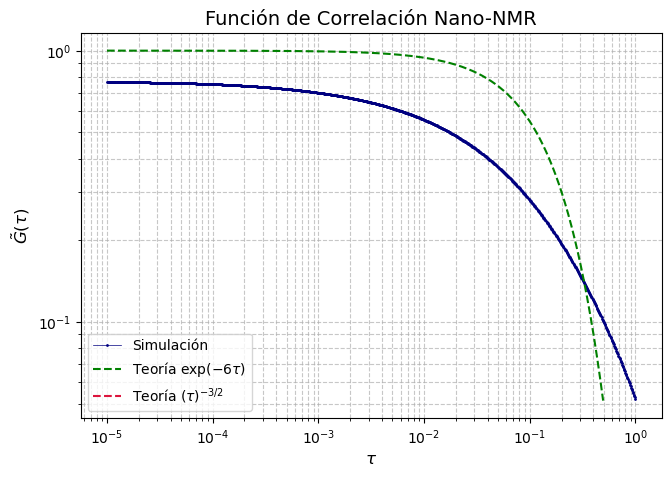

In [13]:
# ------------------ Example usage ------------------------------------------------
if __name__ == "__main__":
    # ejemplo (nm, µs)
    d = 1.0       # nm
    R = L = 5*d   # nm
    D = 1.0        # nm^2/µs (equiv a 1e-9 m^2/s)
    m_max = 100
    p_max = 100
    n_rho = 1000
    n_z = 1000

    print("Precomputando modos (Gauss)...")
    modes = precompute_modes_gauss(R, L, d, D, m_max, p_max, n_rho=n_rho, n_z=n_z)
    print("Hecho. Evaluando G(t) vectorizado...")
    times_us = np.logspace(-5, 0, 1000)  # µs
    tau_vals=times_us*D/d**2
    Gvals = G_bulk_vectorized(times_us, modes)
    np.savetxt("data/G_vs_t.dat", np.c_[times_us, tau_vals, Gvals], header="Tiempo(s) Tau G(t)", fmt="%.9e")

    # gráfica
    import matplotlib.pyplot as plt
    plt.figure(figsize=(7.5,5))
    plt.loglog(tau_vals, Gvals, "o-", label="Simulación", color="navy", markersize=1, linewidth=0.5)
    plt.plot(tau_vals[tau_vals<0.5], np.exp(-6*tau_vals[tau_vals<0.5]), "--", label=r"Teoría $\exp(-6\tau)$", color="green", linewidth=1.5)
    plt.plot(tau_vals[(tau_vals>=1)&(tau_vals<=1000)], (tau_vals[(tau_vals>=1)&(tau_vals<=1000)])**-1.5, "--", label=r"Teoría $(\tau)^{-3/2}$", color="crimson", linewidth=1.5)
    # plt.xlabel("Tiempo (s)", fontsize=12)
    plt.xlabel(r"$\tau$", fontsize=12)
    plt.ylabel(r"$\tilde{G}(\tau)$", fontsize=12)
    plt.title("Función de Correlación Nano-NMR", fontsize=14)
    plt.legend()
    plt.grid(which="both", ls='--', alpha=0.7)
    # plt.savefig("figuras/correlacion_nanoNMR.pdf", bbox_inches="tight", dpi=300)
    plt.show()
    plt.close()

# Harmonic measure — objetivo y fórmulas

En el límite de tiempos largos ($t\gg \tau_v$) la contribución asintótica a la autocorrelación proviene
de la distribución de partículas en la superficie según la *harmonic measure*, que es la derivada
saliente del *Green function* (tiempo-integral del propagador) sobre las superficies del cilindro.

El objetivo numérico de esta sección es evaluar

$$
G(t\gg\tau_v) \;=\; \int_V \frac{Y_2^0(r_0)}{r_0^3}
\left\{ \int_S \left[-\frac{\partial}{\partial n} G(r,r_0)\right] \frac{Y_2^0(r)}{r^3}\,dS \right\} dV,
$$

donde el Green function modal puede escribirse (componentes par / impar)

$$
G(r,r_0) \;=\; \frac{P^{\mathrm{even}}}{\beta_{p}^2 + \frac{4m^2\pi^2}{L^2}}
+\frac{P^{\mathrm{odd}}}{\beta_{p}^2 + \frac{(2m-1)^2\pi^2}{L^2}}.
$$

A continuación implementaremos numéricamente las densidades armónicas en las tres superficies:
el **wall** lateral $\rho=R$, y las **top / bottom caps** $z=d+L$ y $z=d$. Después calcularemos

$$
G(t\gg\tau_v) \;=\; \frac{8\pi^2}{V}\sum_{m,p}\iint_{V} W(\rho_0,z_0)\, \Big[
I_{\text{bottom}}(\rho_0,z_0) + I_{\text{top}}(\rho_0,z_0) + I_{\text{wall}}(\rho_0,z_0)
\Big] d\rho_0 dz_0,
$$

donde $W(\rho,z)=\rho\left[\dfrac{3z^2}{(\rho^2+z^2)^{5/2}}-\dfrac{1}{(\rho^2+z^2)^{3/2}}\right]$
es el kernel dipolar (ya usado en la parte modal) y las integrales de superficie $I_{\cdot}$ se
definen según las fórmulas deducidas (ver celdas siguientes).

In [14]:
def scale_nodes_weights(x, w, a, b):
    # scale from [-1,1] to [a,b]
    nodes = 0.5*(b-a)*x + 0.5*(b+a)
    weights = 0.5*(b-a)*w
    return nodes, weights

In [15]:
# ---------------- Cell: precompute tables needed by the harmonic-measure code (ADIMENSIONAL) ----------------
def precompute_harmonic_tables(R, L, d, m_max, p_max, rho_nodes, z_nodes, rho_weights, z_weights):
    """
    Precompute arrays used to evaluate harmonic densities on surfaces.
    IMPORTANT: rho_nodes must be ADIMENSIONAL in [0,1].
               z_nodes must be ADIMENSIONAL in [1, 1+L_d] where L_d = L/d.
    Inputs:
      - R, L, d: geometry (physical units, e.g. nm)  <-- only used to compute R_d,L_d
      - m_max, p_max: truncation for sums
      - rho_nodes (n_rho,), z_nodes (n_z,) and rho_weights, z_weights: Gauss nodes/weights
    Returns dict with:
      - zeros, betas (adimensional), J1_at_zeros
      - J0_vals (p_max, n_rho) computed with adimensional rho_nodes
      - sin_axial (m_max, n_z), cos_axial (m_max, n_z)
      - k_m (m_max,), kprime_m (m_max,)
      - stored nodes/weights and dims
    """
    # adimensional geometry
    R_d = R / d
    L_d = L / d

    # Bessel zeros and betas: use alpha_{p} / R_d  (adimensional)
    zeros = special.jn_zeros(0, p_max)          # alpha_{0,p}
    betas = zeros / R_d                         # adimensional betas
    J1_at_zeros = special.j1(zeros)            # J1(alpha_{0,p})

    n_rho = rho_nodes.size
    n_z = z_nodes.size

    # Precompute J0(beta * rho_nodes) with rho_nodes adimensional in [0,1]
    J0_vals = np.zeros((p_max, n_rho), dtype=np.float64)
    for p in range(p_max):
        J0_vals[p, :] = special.j0(betas[p] * rho_nodes)

    # axial functions at adimensional nodes (centered at z_center = 1 + L_d/2)
    sin_axial = np.zeros((m_max, n_z), dtype=np.float64)
    cos_axial = np.zeros((m_max, n_z), dtype=np.float64)
    k_m = np.zeros(m_max, dtype=np.float64)
    kprime_m = np.zeros(m_max, dtype=np.float64)
    z_center = 1.0 + 0.5 * L_d

    for m in range(1, m_max + 1):
        km = 2.0 * m * math.pi / L_d        # adimensional axial wavenumbers
        kpm = (2.0 * m - 1.0) * math.pi / L_d
        k_m[m - 1] = km
        kprime_m[m - 1] = kpm
        sin_axial[m - 1, :] = np.sin(km * (z_nodes - z_center))
        cos_axial[m - 1, :] = np.cos(kpm * (z_nodes - z_center))

    return {
        'zeros': zeros,
        'betas': betas,
        'J1_at_zeros': J1_at_zeros,
        'J0_vals': J0_vals,
        'sin_axial': sin_axial,
        'cos_axial': cos_axial,
        'k_m': k_m,
        'kprime_m': kprime_m,
        'rho_nodes': rho_nodes,
        'z_nodes': z_nodes,
        'rho_weights': rho_weights,
        'z_weights': z_weights,
        'n_rho': n_rho,
        'n_z': n_z,
        'm_max': m_max,
        'p_max': p_max,
        'R': R, 'L': L, 'd': d,
        'R_d': R_d, 'L_d': L_d
    }

## Fórmulas discretas para las densidades armónicas (resumen)

Para $n=0$ (simetría angular) las expresiones que implementamos son exactamente las que dedujiste:

**Wall (lateral, $\rho=R$)**:
$$
\omega_{\rho=R}(z;\rho_0,z_0) \;=\; \sum_{p,m}
\frac{\beta_p\,J_0(\beta_p\rho_0)}{J_1(\alpha_p R)}\left[
\frac{\sin(k_m z)\sin(k_m z_0)}{\beta_p^2 + k_m^2}
+
\frac{\cos(k'_m z)\cos(k'_m z_0)}{\beta_p^2 + (k'_m)^2}
\right],
$$
donde $k_m=2m\pi/L$ y $k'_m=(2m-1)\pi/L$.

**Top / Bottom caps**:
$$
\omega_{\text{bottom}}(\rho;\rho_0,z_0) \;=\; -\omega_{\text{top}}(\rho;\rho_0,z_0)
= \sum_{p,m} \frac{J_0(\beta_p \rho)\,J_0(\beta_p \rho_0)}{J_1(\alpha_p R)^2}
\left[
\frac{(-1)^m 2m\pi}{L(\beta_p^2 + k_m^2)}\sin(k_m z_0)
+
\frac{(-1)^m (2m-1)\pi}{L(\beta_p^2 + (k'_m)^2)}\cos(k'_m z_0)
\right].
$$

En discretización Gauss (con `rho_nodes`, `z_nodes`, `rho_weights`, `z_weights`) las integrales
sobre las superficies se convierten en sumas ponderadas. En la implementación numérica evaluamos
para cada punto inicial $(\rho_0,z_0)$ la suma sobre las superficies y luego multiplicamos por
el kernel volumétrico $W(\rho_0,z_0)$ y el peso de cuadratura correspondiente.


### Precomputación vectorizada: qué y por qué

Precomputamos dos objetos principales (por cada índice axial $iz0$ del punto inicial):

1. $$K_{ir\_surf,\,ir0}^{(iz0)} \;=\; \sum_{p}\frac{J_0(\beta_p\rho_{ir\_surf})\,J_0(\beta_p\rho_{ir0})}{J_1(\alpha_p)^2}\;S_p(z_0),$$
   con
   $$
   S_p(z_0)=\sum_m\left[A_{mp}\sin(k_m z_0)+B_{mp}\cos(k'_m z_0)\right],
   $$
   y $$A_{mp},B_{mp}$$ calculados vectorizadamente.

   - $K^{(iz0)}$ es una matriz de tamaño $(n_\rho\times n_\rho)$ que, multiplicada por el kernel de la tapa y los pesos de cuadratura, da $I_{\text{bottom}}$ y $I_{\text{top}}$ para ese $z_0$.

2. $$H_{iz\_surf,\,ir0}^{(iz0)} \;=\; \sum_{p}\frac{\beta_p J_0(\beta_p\rho_{ir0})}{J_1(\alpha_p)}\;U_p(z_{iz\_surf},z_0),$$
   con
   $$
   U_p(z,z_0)=\sum_m\left[\frac{\sin(k_m z)\sin(k_m z_0)}{\beta_p^2+k_m^2}+\frac{\cos(k'_m z)\cos(k'_m z_0)}{\beta_p^2+(k'_m)^2}\right].
   $$

   - $H^{(iz0)}$ es una matriz $(n_z\times n_\rho)$ que, multiplicada por el kernel lateral y los pesos axiales, da $I_{\text{wall}}$ para ese $z_0$.

**Ventaja clave:** todo el coste modal $(m,p)$ queda resuelto con multiplicaciones de matrices y productos tensores de `NumPy` (BLAS), mucho más rápidos que los loops Python/numba sobre modos.

### Detalle implementacional de la precomputación

- Calculamos las matrices modales $A_{mp}$ y $B_{mp}$ vectorizadamente mediante broadcasting:
  $$
  A_{mp} = \frac{(-1)^m k_m}{\beta_p^2 + k_m^2},\qquad
  B_{mp} = \frac{(-1)^m k'_m}{\beta_p^2 + (k'_m)^2},
  $$
  donde $k_m=2m\pi/L$, $k'_m=(2m-1)\pi/L$ y $\beta_p$ ya viene de los ceros de $J_0$.

- Construimos $S_p(z_0) = \sum_m (A_{mp}\sin(k_m z_0) + B_{mp}\cos(k'_m z_0))$ como
  $$
  S_{p,z_0} = (A^T \cdot \sin\_axial[:,z_0]) + (B^T \cdot \cos\_axial[:,z_0]),
  $$
  generando la matriz $(p,n_z)$ $Ssum\_p\_by\_iz0$.

- Para $K^{(iz0)}$: multiplicamos $J0\_vals * (S_{p,z_0}/J1^2)$ y luego hacemos $M^T@J0\_vals$ para obtener la matriz $(n_\rho,n_\rho)$.

- Para $H^{(iz0)}$: construimos $S_{iz\_surf,p}$ (sumas sobre $m$ con inv denominadores) y luego $S@C$ donde $C_{p,ir0}=\beta_p J_0(\beta_p\rho_{ir0})/J_1(\alpha_p)$.

- Estas operaciones usan producto matricial optimizado y no requieren bucles sobre $m,p$ en Python.


In [16]:
# ---------------- Cell: precompute_harmonic_surface_tables_fast (ADIMENSIONAL) ----------------
def precompute_harmonic_surface_tables_fast(
    betas, J1_at_zeros, J0_vals, sin_axial, cos_axial,
    k_m, kprime_m,
    rho_nodes, z_nodes, rho_weights, z_weights,
    m_max, p_max, L_d):
    """
    Precompute compact arrays used by the numba core (adimensional).
    Returns:
      - Ssum_p_by_iz0 (p, n_z) : sum over m of (coeff*axial(z0))/L_d  used for bottom/top K matrices
      - C_all (p, n_rho) : beta_p * J0_vals / J1  used for the wall H contributions
      - J0_vals (p, n_rho), denom_p (p,)
      - inv_den_e, inv_den_o (m,p) optionally
    NOTE: all arguments are adimensional (rho in [0,1], z in [1,1+L_d])
    """
    # arrays
    betas_arr = betas
    beta2_sq = betas_arr**2    # (p,)

    km = k_m.copy()            # (m,)
    kpm = kprime_m.copy()
    km2 = km**2
    kpm2 = kpm**2

    # inv denominators shape (m,p)
    inv_den_e = 1.0 / (km2[:, None] + beta2_sq[None, :])   # 1/(beta^2 + km^2)
    inv_den_o = 1.0 / (kpm2[:, None] + beta2_sq[None, :])

    # coefficients (without the (-1)^m sign: we'll include sign via (-1)**m pattern)
    m_idx = np.arange(1, m_max + 1)
    coef_sin = (2.0 * m_idx * math.pi)   # numerator for sin term (the (-1)^m factor will be applied)
    coef_cos = ((2.0 * m_idx - 1.0) * math.pi)

    # include (-1)^m factor (Mathematica uses (-1)^m in top/bottom contributions)
    signs = (-1.0) ** m_idx              # shape (m,)
    coef_sin_signed = signs * coef_sin   # (m,)
    coef_cos_signed = signs * coef_cos

    # Build Ssum_p_by_iz0[p, iz0] = sum_m [ coef_sin_signed[m] * sin_axial[m,iz0] * inv_den_e[m,p] / L_d
    #                                    + coef_cos_signed[m] * cos_axial[m,iz0] * inv_den_o[m,p] / L_d ]
    # shapes: inv_den_e (m,p) ; sin_axial (m,n_z)
    term_e = np.einsum('mp,mz->pz', (inv_den_e * (coef_sin_signed[:, None] / L_d)), sin_axial)
    term_o = np.einsum('mp,mz->pz', (inv_den_o * (coef_cos_signed[:, None] / L_d)), cos_axial)
    Ssum_p_by_iz0 = term_e + term_o   # (p, n_z)

    denom_p = (J1_at_zeros**2).astype(np.float64)

    # C_all for wall contributions (p, n_rho) = beta_p * J0( beta_p * rho_nodes ) / J1(alpha_p)
    C_all = (betas[:, None] * J0_vals) / J1_at_zeros[:, None]

    return {
        'Ssum_p_by_iz0': Ssum_p_by_iz0,   # (p, n_z)
        'C_all': C_all,                   # (p, n_rho)
        'J0_vals': J0_vals,               # (p, n_rho)
        'denom_p': denom_p,               # (p,)
        'inv_den_e': inv_den_e,           # (m,p)
        'inv_den_o': inv_den_o
    }

### Núcleo `numba` ligero: qué hace y por qué

La función compilada con `numba` **solo** realiza:

1. Recorrido paralelo sobre puntos iniciales indexados por $idx0$ (orden flattened: $\rho$ externo, $z$ interno).
2. Para cada $idx0$:
   - extrae la columna correspondiente de $K^{(iz0)}$ para calcular $I_{\text{bottom}}$ y $I_{\text{top}}$:
     $$I_{\text{bottom}}(\rho_0,z_0)=\sum_{ir\_surf} K^{(iz0)}_{ir\_surf,ir0}\;W_{\text{bottom}}(\rho_{ir\_surf})\;w^\rho_{ir\_surf}.$$
   - extrae la columna correspondiente de $H^{(iz0)}$ para calcular $I_{\text{wall}}$:
     $$I_{\text{wall}}(\rho_0,z_0)=\sum_{iz\_surf} H^{(iz0)}_{iz\_surf,ir0}\;W_{\text{wall}}(z_{iz\_surf})\;w^z_{iz\_surf}.$$
   - acumula $W(\rho_0,z_0)\,[I_{\text{bottom}}+I_{\text{top}}+R I_{\text{wall}}]\,w_{r_0}$.

**Ventajas:**

- No hay bucles sobre $m,p$ dentro del código JIT.
- El trabajo pesado está en operaciones BLAS/NumPy previas; el núcleo `numba` solo suma productos ya compactos.
- Fácil paralelizar sobre $idx0$ con `prange`.

In [17]:
# ---------------- Cell: numba core that avoids building full K_by_iz0 (ADIMENSIONAL) ----------------
@njit(parallel=True, fastmath=True)
def compute_G_infty_numba_streamed(
    Ssum_p_by_iz0, C_all, J0_vals, denom_p,
    rho_nodes, z_nodes, rho_weights, z_weights,
    W_r0_flat, weights_r0_flat,
    R_d, L_d, d_dummy,
    n_rho, n_z, m_max, p_max,
    sin_axial, cos_axial, betas, k_m, kprime_m):
    """
    Numba-compiled streaming core to compute the raw modal sum in adimensional variables.
    - rho_nodes in [0,1]
    - z_nodes in [1, 1+L_d]
    - R_d = R/d, L_d = L/d
    Returns total_vol_sum (no prefactor).
    """
    npoints0 = W_r0_flat.shape[0]
    total_vol_sum = 0.0

    beta2_sq = betas**2
    km2 = k_m**2
    kpm2 = kprime_m**2

    # loop over initial volume nodes
    for idx0 in prange(npoints0):
        ir0 = idx0 // n_z
        iz0 = idx0 % n_z
        rho0 = rho_nodes[ir0]
        z0 = z_nodes[iz0]
        W0 = W_r0_flat[idx0]
        w0 = weights_r0_flat[idx0]

        # bottom/top integrals (radial surface quadrature)
        I_bottom = 0.0
        I_top = 0.0

        # sum over surface radial nodes
        for ir_surf in range(n_rho):
            # build Kval = sum_p ( J0[p,ir_surf] * J0[p,ir0] * Ssum_p_by_iz0[p, iz0] / denom_p[p] )
            Kval = 0.0
            for p in range(p_max):
                dp = denom_p[p]
                if dp == 0.0:
                    continue
                J0_rho_s = J0_vals[p, ir_surf]
                J0_rho0 = J0_vals[p, ir0]
                Kval += (J0_rho_s * J0_rho0) * (Ssum_p_by_iz0[p, iz0] / dp)

            # bottom kernel (adimensional): z_d = 1 (bottom at z=1)
            rho_s = rho_nodes[ir_surf]
            den_b = rho_s*rho_s + 1.0
            Wb = rho_s * (3.0 * 1.0 * 1.0 * den_b**(-2.5) - den_b**(-1.5))
            # top kernel (adimensional): z_d = 1 + L_d
            den_t = rho_s*rho_s + (1.0 + L_d)*(1.0 + L_d)
            Wt = - rho_s * (3.0 * (1.0 + L_d)*(1.0 + L_d) * den_t**(-2.5) - den_t**(-1.5))

            w_surf_rho = rho_weights[ir_surf]
            I_bottom += Kval * Wb * w_surf_rho
            I_top    += Kval * Wt * w_surf_rho  # Wt already includes sign (-)

        # wall integral: integrate over axial surface nodes z_surf
        I_wall = 0.0
        for iz_surf in range(n_z):
            z_s = z_nodes[iz_surf]
            # compute Hval = sum_p C_all[p, ir0] * ( sum_m sin(km z_s)*sin(km z0)/den_e + cos(kpm z_s)*cos(kpm z0)/den_o )
            Hval = 0.0
            for p in range(p_max):
                dp = denom_p[p]
                if dp == 0.0:
                    continue
                Cpr = C_all[p, ir0]   # beta_p * J0(beta_p * rho0) / J1(alpha_p)
                sum_e = 0.0
                sum_o = 0.0
                for m in range(m_max):
                    inv_e = 1.0 / (km2[m] + beta2_sq[p])
                    inv_o = 1.0 / (kpm2[m] + beta2_sq[p])
                    sum_e += sin_axial[m, iz_surf] * sin_axial[m, iz0] * inv_e
                    sum_o += cos_axial[m, iz_surf] * cos_axial[m, iz0] * inv_o
                Hval += Cpr * (sum_e + sum_o)

            denom_w = 1.0 + z_s*z_s   # because radial coordinate at wall = 1 (adimensional)
            Ww = 3.0 * z_s*z_s * denom_w**(-2.5) - denom_w**(-1.5)
            w_surf_z = z_weights[iz_surf]
            I_wall += Hval * Ww * w_surf_z

        total_vol_sum += W0 * (I_bottom + I_top + R_d * I_wall) * w0

    return total_vol_sum

Nota: la función anterior devuelve la suma discreta $\sum_{r_0} W(r_0) [I_{bottom}+I_{top}+R I_{wall}] w_{r_0}$. El factor geométrico $\dfrac{8\pi^2}{V}$ se aplica fuera (como en la parte modal).

### Wrapper de alto nivel: `G_infty_harmonic_fast`

El wrapper realiza:

1. Construcción del mesh flattened ($\rho$ exterior, $z$ interior), cálculo de $W(\rho_0,z_0)$ y pesos flattened.
2. Llamada a `precompute_harmonic_surface_tables(...)` (todas las sumas modales vectorizadas).
3. Construcción de los kernels superficiales $W_{\text{bottom}}(\rho)$, $W_{\text{top}}(\rho)$ y $W_{\text{wall}}(z)$.
4. Llamada al núcleo `numba` ligero `compute_G_infty_numba_light(...)` que devuelve la suma cruda.
5. Aplicación del prefactor geométrico:
   $$
   G_{\infty} = \frac{8\pi^2}{V}\times\text{raw\_sum},\qquad V=\pi R^2 L.
   $$

Colocar esta celda justo después de la precomputación y antes de la evaluación final.


In [18]:
# ---------------- Cell: wrapper safe that checks resource warnings (ADIMENSIONAL) ----------------
import time
def G_infty_harmonic_fast_timed_safe(tables, R, L, d, m_max, p_max, n_rho, n_z, verbose=True):
    """
    High-level wrapper. Expects `tables` = output of precompute_harmonic_tables
    and nodes to be ADIMENSIONAL: rho in [0,1], z in [1,1+L/d].
    Returns Ginf (a scalar) and timing/info dict.
    """
    betas = tables['betas']; J1_at_zeros = tables['J1_at_zeros']; J0_vals = tables['J0_vals']
    sin_axial = tables['sin_axial']; cos_axial = tables['cos_axial']
    k_m = tables['k_m']; kprime_m = tables['kprime_m']
    rho_nodes = tables['rho_nodes']; z_nodes = tables['z_nodes']
    rho_weights = tables['rho_weights']; z_weights = tables['z_weights']
    n_rho = tables['n_rho']; n_z = tables['n_z']
    R_d = tables['R_d']; L_d = tables['L_d']

    # flattened volume mesh (adimensional coordinates)
    rho_flat = np.repeat(rho_nodes, n_z)
    z_flat = np.tile(z_nodes, n_rho)
    weights_flat = np.repeat(rho_weights, n_z) * np.tile(z_weights, n_rho)
    W_r0_flat = W_rz_vec(rho_flat, z_flat)   # W_rz_vec must accept adimensional coords (rho in [0,1], z in [1,1+L_d])

    t0 = time.time()
    pre = precompute_harmonic_surface_tables_fast(
        betas, J1_at_zeros, J0_vals, sin_axial, cos_axial,
        k_m, kprime_m,
        rho_nodes, z_nodes, rho_weights, z_weights,
        m_max, p_max, L_d
    )
    t1 = time.time()
    if verbose:
        print(f"precompute_harmonic_surface_tables_fast time: {t1-t0:.3f} s")

    # call numba core
    raw_sum = compute_G_infty_numba_streamed(
        pre['Ssum_p_by_iz0'], pre['C_all'], pre['J0_vals'], pre['denom_p'],
        rho_nodes.astype(np.float64), z_nodes.astype(np.float64),
        rho_weights.astype(np.float64), z_weights.astype(np.float64),
        W_r0_flat.astype(np.float64), weights_flat.astype(np.float64),
        R_d, L_d, d,    # pass R_d, L_d; d is not used by core but kept for signature similarity
        n_rho, n_z, m_max, p_max,
        sin_axial=tables['sin_axial'], cos_axial=tables['cos_axial'],
        betas=tables['betas'], k_m=tables['k_m'], kprime_m=tables['kprime_m']
    )
    t2 = time.time()
    if verbose:
        print(f"numba core time: {t2-t1:.3f} s (incluye compilación la primera vez)")

    V = math.pi * (R_d * R_d) * L_d
    prefactor = 8.0 * math.pi**2 / V
    Ginf = prefactor * raw_sum
    if verbose:
        print(f"Total time precompute+core: {t2-t0:.3f} s")
    return Ginf, {'t_pre': t1-t0, 't_core': t2-t1, 'raw_sum': raw_sum}

In [19]:
# ============================================
# MODE-BY-MODE DIAGNOSTICS (FINAL, CLEAN)
# Compatible with adimensional modal calculation
# ============================================

import numpy as np
import matplotlib.pyplot as plt
import math

def modal_diagnostics(tables):

    print("=== MODE-BY-MODE diagnostics (adimensional) ===")

    # Extract from tables
    betas   = np.array(tables['betas'])
    J1      = np.array(tables['J1_at_zeros'])
    J0_vals = np.array(tables['J0_vals'])
    sin_ax  = np.array(tables['sin_axial'])
    cos_ax  = np.array(tables['cos_axial'])
    k_m     = np.array(tables['k_m'])
    kpm     = np.array(tables['kprime_m'])

    n_rho = tables['n_rho']
    n_z   = tables['n_z']
    L_d   = tables['L']

    # Pick a representative point (center of grid)
    ir0 = n_rho // 2
    iz0 = n_z   // 2

    # Bounds for diagnostics
    m_max = min(100, tables['m_max'])
    p_max = min(200, tables['p_max'])

    # Safety: ensure J0_vals has shape (p,n_rho)
    if J0_vals.shape[1] != n_rho:
        J0_vals = J0_vals.T

    # ----- Build matrix C[m,p] -----
    # Mode contributions:
    #   C_mp =  (J0_p(rho0)^2 / J1_p^2) * [ (-1)^m * ( 2mπ/L / (β_p^2 + k_m^2) ) sin 
    #                                       + (-1)^m * ( (2m-1)π/L / (β_p^2 + kpm^2) ) cos ]
    #
    C = np.zeros((m_max, p_max), dtype=np.float64)

    for m_idx in range(m_max):

        m = m_idx + 1
        sign = -1.0 if (m % 2 == 1) else 1.0  # (-1)^m

        sin_z0 = sin_ax[m_idx, iz0]
        cos_z0 = cos_ax[m_idx, iz0]

        km2   = k_m[m_idx]**2
        kpm2_ = kpm[m_idx]**2

        coef_sin = (2.0 * m * math.pi) / L_d
        coef_cos = ((2.0 * m - 1.0) * math.pi) / L_d

        for p in range(p_max):

            J0sq = J0_vals[p, ir0] * J0_vals[p, ir0]
            denom = J1[p] * J1[p]

            beta2 = betas[p] * betas[p]

            term_sin = coef_sin * sin_z0 / (beta2 + km2)
            term_cos = coef_cos * cos_z0 / (beta2 + kpm2_)

            C[m_idx, p] = (J0sq / denom) * sign * (term_sin + term_cos)

    # ----- PLOTS -----

    # several m values → cumulative over p
    inds_m = [0, 1, 2, min(5, m_max-1), m_max-1]
    for m_plot in inds_m:
        cum = np.cumsum(C[m_plot, :])
        plt.plot(np.arange(1, p_max+1), cum, label=f"m={m_plot+1}")
    plt.xlabel("p")
    plt.ylabel("cumsum in p")
    plt.title("Cumulative over p for selected m")
    plt.grid(True); plt.legend()
    plt.show()

    # several p values → cumulative over m
    inds_p = [0, 1, 2, min(5, p_max-1), p_max-1]
    for p_plot in inds_p:
        cum = np.cumsum(C[:, p_plot])
        plt.plot(np.arange(1, m_max+1), cum, label=f"p={p_plot+1}")
    plt.xlabel("m")
    plt.ylabel("cumsum in m")
    plt.title("Cumulative over m for selected p")
    plt.grid(True); plt.legend()
    plt.show()

    # ---- numerical outputs ----
    total_by_p = np.sum(C, axis=0)
    total_by_m = np.sum(C, axis=1)

    print("total_by_p[:12] =", np.round(total_by_p[:12], 6))
    print("total_by_m[:12] =", np.round(total_by_m[:12], 6))
    print("Total sum over m,p =", np.sum(C))

    print("=== end diagnostics ===")

    return C

In [20]:
if __name__ == "__main__":

    # ejemplo (usar d=1 nm, R=5*d, L=5*d como en Mathematica)
    d = 1.0
    R = 5.0 * d
    L = 5.0 * d

    # dimensiones adimensionales
    R_d = R / d
    L_d = L / d

    # construir nodos Gauss en adimensionales:
    n_rho = 150
    n_z = 150
    xr, wr = np.polynomial.legendre.leggauss(n_rho)
    xz, wz = np.polynomial.legendre.leggauss(n_z)

    # IMPORTANT: rho in [0,1], z in [1, 1+L_d]
    rho_nodes, rho_weights = scale_nodes_weights(xr, wr, 0.0, 1.0)
    z_nodes,   z_weights   = scale_nodes_weights(xz, wz, 1.0, 1.0 + L_d)

    # precompute
    m_max = 150
    p_max = 150
    tables = precompute_harmonic_tables(R, L, d, m_max, p_max, rho_nodes, z_nodes, rho_weights, z_weights)

    # call wrapper
    Ginf, info = G_infty_harmonic_fast_timed_safe(tables, R, L, d, m_max, p_max, n_rho, n_z, verbose=True)
    print("G(t->infty) =", Ginf, "info:", info)


precompute_harmonic_surface_tables_fast time: 0.004 s
numba core time: 78.671 s (incluye compilación la primera vez)
Total time precompute+core: 78.674 s
G(t->infty) = -0.02555022344870699 info: {'t_pre': 0.0037572383880615234, 't_core': 78.67057180404663, 'raw_sum': -0.12707638621763034}


=== MODE-BY-MODE diagnostics (adimensional) ===


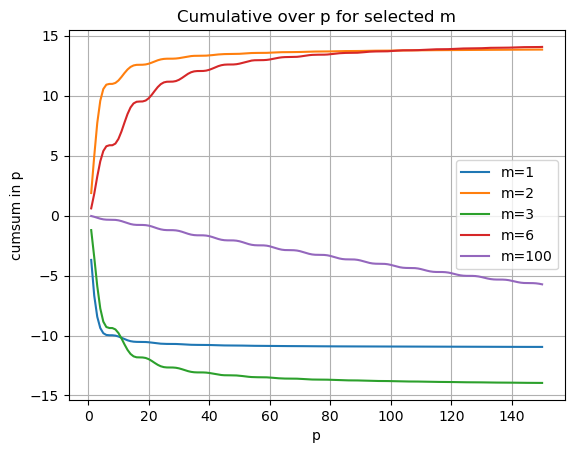

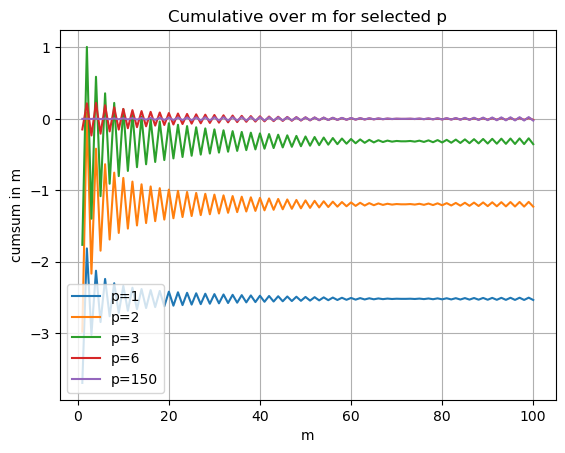

total_by_p[:12] = [-2.535606e+00 -1.229132e+00 -3.547840e-01 -1.001170e-01 -3.670900e-02
 -1.459000e-02 -3.102000e-03 -1.430000e-04 -6.073000e-03 -1.845000e-02
 -3.232700e-02 -4.219200e-02]
total_by_m[:12] = [-10.95193   13.848641 -13.955091  13.920892 -13.96855   14.070281
 -14.192204  14.31515  -14.429557  14.530746 -14.616402  14.685374]
Total sum over m,p = -6.991504174174838
=== end diagnostics ===


In [21]:
C = modal_diagnostics(tables)

### Notas numéricas y recomendaciones

- La implementación está pensada para reutilizar las mismas mallas Gauss de la parte modal (nodos y pesos).
- La función `compute_G_infty_numba` está paralelizada sobre los puntos iniciales y debe compilarse en la primera ejecución (numba JIT).
- Coste y memoria:
  - la complejidad escala aproximadamente como $O(N_{\text{vol}} \cdot m_{\max}\cdot p_{\max})$,
    con $N_{\text{vol}}=N_\rho N_z$ el número de puntos de volumen. Ajusta $m_{\max}$ y $p_{\max}$
    para balancear precisión / tiempo.
- Convergencia:
  - prueba con (por ejemplo) $m_{\max},p_{\max}=8,12,16$ y compara cambios relativos.
  - aumenta `n_rho` y `n_z` (Gauss) para verificar convergencia espacial.
- Precisión y estabilidad:
  - cuidado con $J1(\alpha_{p})$ muy pequeño — en la práctica `special.j1(zeros)` no es cero y el denominador
    es seguro; si quieres, añade un pequeño `eps` en denominadores.
- Validación:
  - comparar con caso de prueba conocido (por ejemplo: una distribución inicial puntual en el centro con pocos modos,
    o verificar la conservación de probabilidad en el kernel integrado).

# Estimación de la medida armónica por Monte Carlo (Walk on Spheres)

En el límite $t \gg \tau_V$, la autocorrelación del campo magnético en el sistema
cilíndrico está determinada por la **medida armónica** $\omega(r | r_0)$, que
describe la distribución de salida de partículas de un proceso de difusión
(Browniano) con condiciones de Dirichlet.

La cantidad buscada es:

$$
G(t \gg \tau_V) = \frac{1}{V} \int_V \frac{Y_2^0(r_0)}{r_0^3}
\left( \int_S \omega(r | r_0) \frac{Y_2^0(r)}{r^3} \, dS \right) dV_0
$$

Si se generan $N$ posiciones iniciales $r_0^{(i)}$ uniformemente distribuidas en
el volumen y para cada una se obtiene un punto de salida $r_{\text{exit}}^{(i)}$
según la medida armónica, el **estimador Monte Carlo** es:

$$
\widehat{G}_N = \frac{1}{N} \sum_{i=1}^N
\frac{Y_2^0(r_0^{(i)})}{r_0^{(i)3}}
\frac{Y_2^0(r_{\text{exit}}^{(i)})}{r_{\text{exit}}^{(i)3}}
$$

De esta forma, $G_\infty$ puede estimarse sin resolver las ecuaciones de
Fick ni calcular el propagador modal, sino directamente por muestreo de la
distribución de salida del proceso de difusión.


In [22]:
# ----- 1. Spherical harmonic Y20/r^3 (dimensionless) -----

Y20_prefactor = math.sqrt(5.0/(16.0*math.pi))

@njit(fastmath=True)
def Y20_over_r3_dimless(rho, z):
    """
    Evaluates Y_2^0(theta)/r^3 in dimensionless coordinates:
       r = sqrt(rho^2 + z^2)
    Avoids singularity by returning 0 at r=0.
    """
    r2 = rho*rho + z*z
    if r2 == 0.0:
        return 0.0
    r = math.sqrt(r2)
    cos_theta = z / r
    return Y20_prefactor * (3.0*cos_theta*cos_theta - 1.0) / (r*r*r)

# Método Walk on Spheres (WOS)

El método **Walk on Spheres** (WOS) permite muestrear eficientemente la
distribución de salida de un proceso Browniano en un dominio arbitrario con
condiciones de frontera absorbentes.

## Idea básica

En un punto $x$ dentro del dominio, se construye la **esfera más grande**
contenida completamente en el dominio. Si su radio es $r(x)$, el punto de salida
del Browniano al abandonar dicha esfera está uniformemente distribuido sobre
su superficie. Por tanto, el siguiente punto del recorrido se obtiene como:

$$
x_{n+1} = x_n + r(x_n) \, \hat{u},
$$

donde $\hat{u}$ es un vector unitario aleatorio isotrópico.

Se repite este proceso hasta que la distancia al borde sea menor que una
tolerancia $\varepsilon$. El punto final se proyecta sobre el borde más cercano,
definiendo así el punto de salida $x_{\text{exit}}$.

## En el cilindro

El dominio es un cilindro de radio $R$ y altura $L$, con su base inferior en $z=d$.

La distancia al borde más cercano es:

$$
r(x) = \min \big\{ R - \sqrt{x^2 + y^2}, \; z - d, \; d + L - z \big\}.
$$

Cuando $r(x) < \varepsilon$, se considera que la partícula ha salido.  
La frontera puede ser:
- **Pared lateral:** $\rho = R$  
- **Base inferior:** $z = d$  
- **Base superior:** $z = d + L$


In [23]:
# ----- 2. Distance to boundary (dimensionless domain) -----

@njit(fastmath=True)
def dist_to_boundary_dimless(x, y, z, R_d, zmin, zmax):
    """
    Domain:
        radial: rho = sqrt(x^2+y^2) <= R_d
        axial:  z ∈ [zmin, zmax] 
    Returns (distance, face_id):
        face_id = 0 → wall (rho = R_d)
                 = 1 → bottom (z = zmin)
                 = 2 → top (z = zmax)
    """
    rho = math.hypot(x, y)

    drad = R_d - rho
    dbot = z - zmin
    dtop = zmax - z

    if drad < dbot:
        if drad < dtop:
            return drad, 0
        else:
            return dtop, 2
    else:
        if dbot < dtop:
            return dbot, 1
        else:
            return dtop, 2

# ----- 3. Uniform step on sphere -----

@njit(fastmath=True)
def rand_unit_vector():
    u1 = np.random.randn()
    u2 = np.random.randn()
    u3 = np.random.randn()
    n = math.sqrt(u1*u1 + u2*u2 + u3*u3)
    if n == 0.0:
        return 1.0, 0.0, 0.0
    return u1/n, u2/n, u3/n

# ----- 4. Walk On Spheres in dimensionless domain -----

@njit(fastmath=True)
def wos_exit_point_dimless(x0, y0, z0, R_d, zmin, zmax, eps):
    """
    Walk on spheres until exit from the dimensionless cylinder.
    Returns (rho_exit, phi_exit, z_exit, face)
    """
    x, y, z = x0, y0, z0
    for _ in range(20000):

        dist, face = dist_to_boundary_dimless(x, y, z, R_d, zmin, zmax)
        if dist <= eps:
            rho = math.hypot(x, y)
            phi = math.atan2(y, x)

            if face == 0:   # wall
                return R_d, phi, z, 0
            elif face == 1: # bottom
                return rho, phi, zmin, 1
            else:           # top
                return rho, phi, zmax, 2

        # take sphere step
        ux, uy, uz = rand_unit_vector()
        x += dist * ux
        y += dist * uy
        z += dist * uz

    # fallback
    rho = math.hypot(x, y)
    phi = math.atan2(y, x)
    return R_d, phi, min(max(z, zmin), zmax), 0

# Control del error en Monte Carlo

El parámetro $\varepsilon$ controla el sesgo de proyección final.  
Valores típicos: $10^{-3}$ nm (muy preciso) o $10^{-2}$ nm (más rápido).

El error estadístico del promedio Monte Carlo decrece como $1/\sqrt{N}$.
Conviene evaluar la desviación estándar muestral y el error estándar:

$$
\mathrm{SE} = \frac{\sigma}{\sqrt{N}}.
$$


In [24]:
# ----- 5. Full Monte Carlo for G(∞) -----

@njit(parallel=True, fastmath=True)
def mc_G_infty_wos_dimless(N, R_d, L_d, eps):
    """
    Fully dimensionless Monte Carlo estimator of G(∞).
    Domain:
        rho ∈ [0,1]
        z   ∈ [1,1+L_d]
    """
    zmin = 1.0
    zmax = 1.0 + L_d

    vals = np.zeros(N, dtype=np.float64)

    for i in prange(N):
        # sample uniformly in volume of dimensionless cylinder
        u = np.random.rand()
        v = np.random.rand()
        w = np.random.rand()

        # rho ∈ [0,1], correct distribution: ρ = sqrt(u)
        rho0 = math.sqrt(u)
        phi0 = 2.0 * math.pi * v
        z0   = zmin + L_d * w

        x0 = rho0 * math.cos(phi0)
        y0 = rho0 * math.sin(phi0)

        # Y20/r^3 at initial point (dimless)
        g0 = Y20_over_r3_dimless(rho0, z0)

        # perform WOS
        rho_e, phi_e, z_e, face = wos_exit_point_dimless(x0, y0, z0, R_d, zmin, zmax, eps)

        # Y20/r^3 at exit
        f_e = Y20_over_r3_dimless(rho_e, z_e)

        vals[i] = g0 * f_e

    # MC estimator of ⟨g0 f_exit⟩
    mean = np.mean(vals)
    std = np.std(vals)
    se   = std / math.sqrt(N)

    # prefactor 8π² / V  with  V = π R_d² L_d
    V = math.pi * R_d*R_d * L_d
    prefactor = 8.0 * math.pi*math.pi / V

    return prefactor * mean, prefactor * se, std

# Interpretación física de los resultados

El valor obtenido de $G_\infty$ representa la contribución estacionaria de las
correlaciones de campo magnético en la superficie del cilindro.

- Si $G_\infty > 0$, las correlaciones son **en fase** entre puntos dentro y fuera.
- Si $G_\infty < 0$, predominan correlaciones **antifásicas**, esperadas en geometrías
  con simetría dipolar (campo $\sim Y_2^0$).

El orden de magnitud esperado es del tipo:
- $10^{-1}$ para $R = L = 5d$
- $10^{-2}$ para $R = L = 10d$
- $10^{-3}$ para $R = L = 20d$

Estos valores son coherentes con los resultados modales del cálculo determinista.


In [25]:
if __name__ == "__main__":

    d = 1.0
    R = 5.0 * d
    L = 5.0 * d

    # dimensionless geometry
    R_d = R/d   # =5
    L_d = L/d   # =5

    eps = 1e-6      # dimensionless tolerance
    N   = int(1e8) # ajusta según el tiempo

    G_est, SE, STD = mc_G_infty_wos_dimless(N, R_d, L_d, eps)

    print("G_inf (MC,WOS,dimless) =", G_est, "±", SE)


G_inf (MC,WOS,dimless) = 0.0008703298945123806 ± 4.0051760267884796e-07


# Contribución dependiente del tiempo desde la superficie

En esta sección analizamos cómo las moléculas que difunden en un cilindro con
condiciones de borde absorbentes contribuyen al correlador dipolar
al **acumularse en la superficie**.

La idea central es:

1. Las partículas comienzan dentro del volumen.
2. Difunden libremente con coeficiente de difusión $D$.
3. Cuando tocan la superficie, son absorbidas.
4. El flujo hacia la superficie se integra en el tiempo.
5. Cada punto de llegada sobre la superficie se pondera con el factor dipolar  
   $$ \frac{Y_2^0}{r^3}. $$

La contribución total tiempo-dependiente es:

$$
G^{\mathrm{surface}}(t)
= -\frac{8\pi^2}{V}\sum_{m=1}^\infty \sum_{p=0}^\infty 
\Bigl[1 - e^{-D\lambda_{p,m} t}\Bigr]\, M_{p,m},
$$

donde:

- $\lambda_{p,m} = \beta_{0,p}^2 + \frac{(2m-1)^2\pi^2}{L^2}$  
  son los autovalores del Laplaciano en el cilindro,
- $M_{p,m}$ contiene la **doble integral** volumen–superficie ponderada por el_


## Geometría y kernels dipolares

Usamos un cilindro con:

- Radio: $R$
- Altura: $L$
- Offset axial: el fondo está en $z=d$ y el tope en $z=d+L$.

El kernel dipolar en coordenadas cilíndricas es:

$$
\frac{Y_2^0}{r^3} = 
\frac{\sqrt{5/(16\pi)}\,(3\cos^2\theta -1)}{r^3}.
$$

Pero para la evaluación en la superficie, basta usar el equivalente:

$$
K(\rho,z) = \frac{3z^2}{(\rho^2+z^2)^{5/2}} -
\frac{1}{(\rho^2+z^2)^{3/2}}.
$$

Superficies:

- **Bottom:** $z = d$
- **Top:** $z = d+L$
- **Wall:** $\rho = R$

Definimos:

$$
K_{\mathrm{bottom}}(\rho),\quad 
K_{\mathrm{top}}(\rho),\quad 
K_{\mathrm{wall}}(z).
$$


In [39]:
# Parámetros y utilidades (ADIMENSIONAL)
import numpy as np
import math
import time
from scipy import special
from functools import partial

# Parámetros físicos / geométricos (ejemplo)
d = 1.0          # referencia (nm)
R = 5.0 * d
L = 5.0 * d
D = 1.0          # nm^2/µs (ejemplo)

# parámetros adimensionales
R_d = R / d      # = 5.0
L_d = L / d      # = 5.0

# prefactor adimensional (volumen adimensional V_d = pi * (R_normalized)^2 * L_d)
# en nuestra convención la malla radial corre en [0,1] y la pared está en rho=1,
# así que usamos V_d = pi * 1^2 * L_d = pi * L_d
V_d = math.pi * (1.0**2) * L_d
PREF = 8.0 * math.pi**2 / V_d   # prefactor final multiplicativo

# función Y_{2}^{0}(theta)/r^3 adimensional (evita r=0)
Y20_prefactor = math.sqrt(5.0/(16.0*math.pi))
def Y20_over_r3(rho, z):
    r2 = rho*rho + z*z
    if r2 == 0.0:
        return 0.0
    r = math.sqrt(r2)
    cos_theta = z / r
    return Y20_prefactor * (3.0 * cos_theta*cos_theta - 1.0) / (r*r*r)

# Kernels dipolares que aparecen en las integrales (adimensional)
def kernel_bottom(rho):
    denom = rho*rho + d*d
    return (3*d*d)*denom**(-2.5) - denom**(-1.5)

def kernel_top(rho):
    z = d + L_d
    denom = rho*rho + z*z
    return (3*z*z)*denom**(-2.5) - denom**(-1.5)

def kernel_wall(z_s):
    denom = R_d*R_d + z_s*z_s
    return (3*z_s*z_s)*denom**(-2.5) - denom**(-1.5)

## Peso volumétrico dipolar dentro del volumen

En la integral de volumen aparece el factor

$$
W(r_0) = \rho_0 
\left[
\frac{3z_0^2}{(\rho_0^2 + z_0^2)^{5/2}}
- 
\frac{1}{(\rho_0^2 + z_0^2)^{3/2}}
\right],
$$

el cual combina:

- el Jacobiano cilíndrico $\rho_0$,
- el kernel dipolar evaluado en el punto inicial $r_0$.

Este peso permite que la integral numérica sea simplemente:

$$
\sum_{\rho_0,z_0} W(r_0)\,(\cdots)\,w_\rho\,w_z.


# **Construcción de los coeficientes modales $M_{p,m}$**

Cada modo en el espectro axial y radial aporta:

$$
M_{p,m}
= \int_V W(r_0)\, \omega_{p,m}(r_{\mathrm{surf}},r_0)\, dV,
$$

donde $\omega_{p,m}$ es la densidad armónica sobre:

- fondo (bottom),
- tope (top),
- pared (wall).

Usamos las expresiones separadas para seno y coseno:

$$
\sin(k_m z),\qquad \cos(k'_m z)
$$

con denominadores:

$$
\frac{1}{\beta_{0,p}^2 + k_m^2},\qquad 
\frac{1}{\beta_{0,p}^2 + k_m'^2}.
$$

El código vectoriza:

1. Integrales en $\rho_{\mathrm{surf}}$ → bottom/top.
2. Integrales en $z_{\mathrm{surf}}$ → wall.
3. Integral de volumen → peso $W_{r_0}$.


## Fórmulas discretizadas

Para implementar las integrales numéricas usamos las reglas de cuadratura asociadas a `rho_nodes, rho_weights` y `z_nodes, z_weights`.

- Integral sobre volumen: $$\iint_V F(\rho_0,z_0)\, \rho_0\, d\rho_0 dz_0 \approx \sum_{i,j} F(\rho_i,z_j)\;\rho_i\;w_{\rho,i}\;w_{z,j}.$$

- Integral sobre la superficie radial (ρ variable, z fijo): $$\int_0^1 \rho\,\omega(\rho,\rho_0,z_0)\,K(\rho)\,d\rho \approx \sum_{k} \omega(\rho_k,\rho_0,z_0)\,K(\rho_k)\, \rho_k \, w_{\rho,k}.$$

- Integral sobre la tapa (ρ variable) es análoga; integral sobre la pared (z variable):
$$\int_{1}^{1+L_d}\omega_{wall}(z,\rho_0,z_0)\,K_{wall}(z)\,dz \approx \sum_\ell \omega_{wall}(z_\ell,\rho_0,z_0)\,K_{wall}(z_\ell)\, w_{z,\ell}.$$

Usaremos estas fórmulas para construir $M_{p,m}$ en forma completamente discreta.


In [40]:
def compute_mode_contributions(tables, verbose=True):

    rho_nodes = tables['rho_nodes']      # 0..R_d
    rho_weights = tables['rho_weights']
    z_nodes   = tables['z_nodes']        # d..d+L_d
    z_weights = tables['z_weights']

    J0_vals = tables['J0_vals']
    J1      = tables['J1_at_zeros']
    betas   = tables['betas']

    sin_ax  = tables['sin_axial']
    cos_ax  = tables['cos_axial']

    m_max = tables['m_max']
    p_max = tables['p_max']
    n_rho = tables['n_rho']
    n_z   = tables['n_z']

    # --- Precompute surface kernels (CORRECT DOMAIN) ---
    Kb_vec = np.array([kernel_bottom(r) for r in rho_nodes])
    Kt_vec = np.array([kernel_top(r) for r in rho_nodes])
    Kw_vec = np.array([kernel_wall(z) for z in z_nodes])

    # --- Precompute dipolar weight in volume ---
    W_r0 = np.zeros((n_rho, n_z))
    for ir in range(n_rho):
        rho0 = rho_nodes[ir]
        for iz in range(n_z):
            z0 = z_nodes[iz]
            denom = rho0*rho0 + z0*z0
            W_r0[ir, iz] = rho0*(3*z0*z0*denom**(-2.5) - denom**(-1.5))

    # --- Allocate ---
    M = np.zeros((p_max, m_max), dtype=np.float64)

    t0 = time.time()

    for p in range(p_max):
        beta = betas[p]
        J1p2 = J1[p]**2

        # radial factor J0(beta rho) evaluated at surface and at volume nodes
        J0_r_surf = J0_vals[p, :]  # for bottom/top (rho_surf ∈ 0..R)
        J0_r0     = J0_vals[p, :]  # for rho0 ∈ 0..R

        # radial integrals for bottom/top
        Kb_p = np.sum(J0_r_surf * Kb_vec * rho_weights)
        Kt_p = np.sum(J0_r_surf * Kt_vec * rho_weights)

        for m_idx in range(m_max):
            m = m_idx + 1

            # (-1)^m factor
            sign = -1.0 if (m % 2 == 1) else 1.0

            # eigenvalues
            den_e = beta*beta + (2*m*np.pi/L_d)**2
            den_o = beta*beta + ((2*m - 1)*np.pi/L_d)**2

            sin_z0 = sin_ax[m_idx, :]
            cos_z0 = cos_ax[m_idx, :]

            coef_sin = sign * (2*m*np.pi)/(L_d * den_e)
            coef_cos = sign * ((2*m - 1)*np.pi)/(L_d * den_o)

            A_z0 = coef_sin * sin_z0 + coef_cos * cos_z0

            factor_rho0 = (J0_r0 / J1p2) * rho_weights
            temp_z = np.tensordot(factor_rho0, W_r0, axes=(0,0))

            I_bottom_total = Kb_p * np.sum(temp_z * A_z0 * z_weights)
            I_top_total    = Kt_p * np.sum(temp_z * (-A_z0) * z_weights)

            # wall
            sin_zs = sin_ax[m_idx, :]
            cos_zs = cos_ax[m_idx, :]

            S_sin = (sin_zs / den_e) * Kw_vec
            S_cos = (cos_zs / den_o) * Kw_vec

            I_sin = np.sum(S_sin * z_weights)
            I_cos = np.sum(S_cos * z_weights)

            factor_rho0_wall = (beta * J0_r0 / J1[p]) * rho_weights
            temp_z_wall = np.tensordot(factor_rho0_wall, W_r0, axes=(0,0))

            Bz = I_sin * sin_z0 + I_cos * cos_z0

            I_wall_total = np.sum(temp_z_wall * Bz * z_weights)

            M[p, m_idx] = I_bottom_total + I_top_total + I_wall_total

        if verbose and p % 10 == 0:
            print(f"p={p}/{p_max} elapsed {time.time()-t0:.1f}s")

    print("Finished compute_mode_contributions")
    return M


# **Cálculo de la contribución temporal**

El correlador superficial se obtiene mediante:

$$
G^{\mathrm{surface}}(t)
= -\frac{8\pi^2}{V}\sum_{p,m} 
\Bigl[1 - e^{-D\lambda_{p,m} t} \Bigr] M_{p,m}.
$$

Usamos la variable adimensional:

$$
\tau = \frac{D t}{d^2}.
$$


In [41]:
def G_surface_vs_time(t_array, M_pm, tables, D, d):

    betas = tables['betas']
    L_d  = tables['L_d']
    m_max = tables['m_max']
    p_max = tables['p_max']

    # t → tau = D t / d^2
    tau_array = (D * np.array(t_array)) / (d*d)

    # spectral lambda_{p,m}
    lamb = np.zeros((p_max, m_max))
    for p in range(p_max):
        for m_idx in range(m_max):
            m = m_idx + 1
            lamb[p, m_idx] = betas[p]**2 + ((2*m - 1)**2 * np.pi**2)/(L_d*L_d)

    G_ts = np.zeros_like(tau_array)

    # geometrical prefactor CORRECTO:
    V_d = np.pi * R_d*R_d * L_d
    PREF = 8 * np.pi * np.pi / V_d

    for i, tau in enumerate(tau_array):
        F = 1.0 - np.exp(-lamb * tau)
        G_ts[i] = -PREF * np.sum(F * M_pm)

    return G_ts


Geometría usada:
  d  = 1.0
  R  = 5.0
  L  = 5.0
  D  = 1.0
--------------------------------------------
Calculando coeficientes modales M_{p,m} ...
p=0/150 elapsed 0.0s
p=10/150 elapsed 0.4s
p=20/150 elapsed 0.7s
p=30/150 elapsed 1.1s
p=40/150 elapsed 1.5s
p=50/150 elapsed 1.8s
p=60/150 elapsed 2.2s
p=70/150 elapsed 2.5s
p=80/150 elapsed 2.8s
p=90/150 elapsed 3.2s
p=100/150 elapsed 3.5s
p=110/150 elapsed 3.8s
p=120/150 elapsed 4.1s
p=130/150 elapsed 4.3s
p=140/150 elapsed 4.6s
Finished compute_mode_contributions
--------------------------------------------------------
Cálculo M_{p,m} terminado. Tiempo total: 4.93 s
Shape M_pm = (150, 150)
--------------------------------------------------------

Calculando G_surface(t) ...
Cálculo G_surface(t) completo. Tiempo: 0.08 s
--------------------------------------------------------



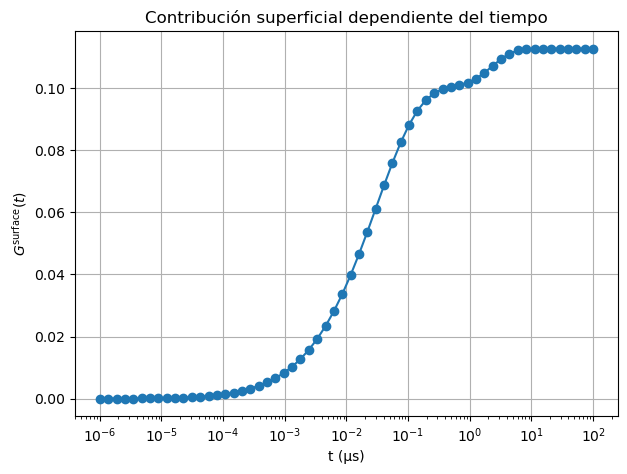

In [44]:
if __name__ == "__main__":
    
    import time
    import numpy as np
    import matplotlib.pyplot as plt

    # ============================
    # 1. Geometría y parámetros
    # ============================

    # Longitud característica d (nm)
    d = 1.0

    # Geometría física
    R_d = 5*d     # radio del cilindro
    L_d = 5*d     # altura del cilindro

    # Difusión (unidades: nm^2 / µs)
    D = 1.0

    print("Geometría usada:")
    print(f"  d  = {d}")
    print(f"  R  = {R_d}")
    print(f"  L  = {L_d}")
    print(f"  D  = {D}")
    print("--------------------------------------------")

    # Las tablas ya deben estar generadas antes.
    # tables = build_tables(...)   # <-- si tuvieras función generadora
    # Aquí asumimos que 'tables' ya existe en memoria.

    # ============================
    # 2. Calcular M_{p,m}
    # ============================

    print("Calculando coeficientes modales M_{p,m} ...")
    t0 = time.time()

    M_pm = compute_mode_contributions(tables, verbose=True)

    t1 = time.time()
    print("--------------------------------------------------------")
    print(r"Cálculo M_{p,m} terminado.",f"Tiempo total: {t1 - t0:.2f} s")
    print("Shape M_pm =", M_pm.shape)
    print("--------------------------------------------------------\n")

    # ============================
    # 3. Calcular G_surface(t)
    # ============================

    print("Calculando G_surface(t) ...")

    # Tiempos en microsegundos
    t_array = np.logspace(-6, 2, 60)

    t2 = time.time()
    G_t = G_surface_vs_time(t_array, M_pm, tables, D=D, d=d)
    t3 = time.time()

    print(f"Cálculo G_surface(t) completo. Tiempo: {t3 - t2:.2f} s")
    print("--------------------------------------------------------\n")

    # ============================
    # 4. Graficar
    # ============================

    plt.figure(figsize=(7,5))
    plt.semilogx(t_array, G_t, '-o')
    plt.grid(True)
    plt.xlabel('t (µs)')
    plt.ylabel(r'$G^{\mathrm{surface}}(t)$')
    plt.title('Contribución superficial dependiente del tiempo')
    plt.show()

In [46]:
# sanity_check.py
import numpy as np, math

# asumimos que ya tienes: tables, M_pm
R_d = tables['R_d']    # o el valor correcto
L_d = tables['L_d']
p_max, m_max = M_pm.shape

V_d = math.pi * R_d*R_d * L_d
PREF = 8.0 * math.pi**2 / V_d

sum_M = np.sum(M_pm)          # suma total M_{p,m}
Gsurf_inf = -PREF * sum_M     # según tu fórmula G_surface(t->inf) = -PREF * sum M

print("sum_M =", sum_M)
print("PREF =", PREF)
print("G_surface(t->inf)  = ", Gsurf_inf)


sum_M = -0.5601304630450611
PREF = 0.20106192982974674
G_surface(t->inf)  =  0.11262091185626963


In [47]:
def compute_mode_contributions_split(tables, verbose=True):
    # copia tu código actual, pero acumula por separado
    rho_nodes   = tables['rho_nodes']; rho_weights = tables['rho_weights']
    z_nodes     = tables['z_nodes'];   z_weights   = tables['z_weights']
    J0_vals = tables['J0_vals']; J1 = tables['J1_at_zeros']; betas = tables['betas']
    sin_ax = tables['sin_axial']; cos_ax = tables['cos_axial']
    m_max = tables['m_max']; p_max = tables['p_max']
    n_rho = tables['n_rho']; n_z = tables['n_z']

    Kb_vec = np.array([kernel_bottom(r) for r in rho_nodes])
    Kt_vec = np.array([kernel_top(r)    for r in rho_nodes])
    Kw_vec = np.array([kernel_wall(z)   for z in z_nodes])

    W_r0 = np.zeros((n_rho, n_z))
    for ir in range(n_rho):
        rho0 = rho_nodes[ir]
        for iz in range(n_z):
            z0 = z_nodes[iz]
            den = rho0*rho0 + z0*z0
            W_r0[ir,iz] = rho0*(3*z0*z0*den**(-2.5) - den**(-1.5))

    M_bot = np.zeros((p_max, m_max))
    M_top = np.zeros((p_max, m_max))
    M_wall = np.zeros((p_max, m_max))

    for p in range(p_max):
        beta = betas[p]
        J1p2 = J1[p]**2
        J0_r_surf = J0_vals[p,:]
        J0_r0 = J0_vals[p,:]

        Kb_p = np.sum(J0_r_surf * Kb_vec * rho_weights)
        Kt_p = np.sum(J0_r_surf * Kt_vec * rho_weights)

        for m_idx in range(m_max):
            m = m_idx+1
            sign = -1.0 if (m % 2 == 1) else 1.0
            den_e = beta*beta + (2*m*np.pi/L_d)**2
            den_o = beta*beta + ((2*m-1)*np.pi/L_d)**2
            sin_z0 = sin_ax[m_idx,:]; cos_z0 = cos_ax[m_idx,:]
            coef_sin = sign * (2*m*np.pi)/(L_d*den_e)
            coef_cos = sign * ((2*m-1)*np.pi)/(L_d*den_o)
            A_z0 = coef_sin*sin_z0 + coef_cos*cos_z0
            factor_rho0 = (J0_r0 / J1p2) * rho_weights
            temp_z = np.tensordot(factor_rho0, W_r0, axes=(0,0))
            I_bottom = Kb_p * np.sum(temp_z * A_z0 * z_weights)
            I_top    = Kt_p * np.sum(temp_z * (-A_z0) * z_weights)
            # wall
            sin_zs = sin_ax[m_idx,:]; cos_zs = cos_ax[m_idx,:]
            S_sin = (sin_zs/den_e)*Kw_vec
            S_cos = (cos_zs/den_o)*Kw_vec
            I_sin = np.sum(S_sin * z_weights); I_cos = np.sum(S_cos * z_weights)
            factor_rho0_wall = (beta*J0_r0/J1[p]) * rho_weights
            temp_z_wall = np.tensordot(factor_rho0_wall, W_r0, axes=(0,0))
            Bz = I_sin*sin_z0 + I_cos*cos_z0
            I_wall = np.sum(temp_z_wall * Bz * z_weights)

            M_bot[p,m_idx] = I_bottom
            M_top[p,m_idx] = I_top
            M_wall[p,m_idx] = I_wall

    return M_bot, M_top, M_wall


In [48]:
M_bot, M_top, M_wall = compute_mode_contributions_split(tables)
sum_bot = np.sum(M_bot); sum_top = np.sum(M_top); sum_wall = np.sum(M_wall)
print("sums: bot, top, wall =", sum_bot, sum_top, sum_wall)
print("total sum M =", sum_bot + sum_top + sum_wall)
print("Gsurf_inf (per surface) =", -PREF*np.array([sum_bot, sum_top, sum_wall]))


sums: bot, top, wall = -0.5645579930562566 0.004569089726177503 -0.00014155971498205832
total sum M = -0.5601304630450612
Gsurf_inf (per surface) = [ 1.13511120e-01 -9.18669998e-04  2.84622695e-05]
